# 3차시 (교사용) | 전국 시·군·구 군집 분석과 지역 맞춤형 인구 정책 제안

**SW·AI 교과융합 수업: 지방소멸위험 데이터 기반의 K-means 군집 분석 PBL**

### 학습목표
- 전국 시·군·구 데이터에 표준화와 K-means를 적용하여 지역 유형을 분류하고, 적절한 군집 수를 정할 수 있다.
- 군집 분석 결과를 근거로 공간 불평등 문제를 해석하고, 지역 맞춤형 인구 정책을 제안할 수 있다.

### 데이터
`korea_2025.csv` : 전국 17개 시도, 229개 시·군·구(경북 데이터에 `시도` 열 추가, 229행 × 6열)

> 자료: 한국고용정보원(KEIS) 지방소멸위험지수 데이터(2025년)를 수업용으로 가공
> 지방소멸위험지수 = 20~39세 여성 인구 ÷ 65세 이상 인구 (0.5 미만이면 소멸위험지역)

**사용 방법:** 위에서부터 차례대로 셀을 실행하세요(Shift + Enter). `___` 부분은 빈칸입니다.

## 0. 준비하기

In [1]:
# ① 데이터가 있는 깃허브 저장소(저장소를 옮길 때만 수정)
REPO = 'choihyeongbae/local-extinction-kmeans'
BASE = f'https://raw.githubusercontent.com/{REPO}/main/data/'
# ② 그래프에서 한글이 보이도록 패키지 설치
!pip install -q koreanize-matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.cluster import KMeans

## 활동1. 전국 데이터 불러오기와 지역 격차 확인
같은 이름의 시·군·구(예: 중구, 동구)가 있으므로 `시도`와 함께 확인합니다.

In [2]:
DATA_URL = BASE + 'korea_2025.csv'
import pandas as pd
df = pd.read_csv(DATA_URL)
pop, old = df['총인구'], df['고령인구']
df['고령인구비율'] = old / pop * 100
df['소멸위험지수'] = df['청년여성인구'] / old
df['소멸위험'] = df['소멸위험지수'] < 0.5
print(df.shape)
n = df['소멸위험'].sum()
print(f"전국 소멸위험지역: {n}개 / {len(df)}개")
# 시도별 소멸위험지역 비율(%)
rate = df.groupby('시도')['소멸위험'].mean() * 100
print(rate.sort_values(ascending=False).round(1))

(229, 9)
전국 소멸위험지역: 144개 / 229개
시도
전북특별자치도    92.9
전라남도       90.9
경상북도       90.9
충청북도       90.9
강원특별자치도    88.9
부산광역시      87.5
경상남도       83.3
충청남도       80.0
대전광역시      60.0
울산광역시      60.0
제주특별자치도    50.0
대구광역시      44.4
인천광역시      30.0
경기도        22.6
광주광역시      20.0
서울특별시       8.0
세종특별자치시     0.0
Name: 소멸위험, dtype: float64


### 수도권과 비수도권 비교하기

In [3]:
# 수도권(서울·경기·인천)과 비수도권 구분
capital = ['서울특별시', '경기도', '인천광역시']
is_cap = df['시도'].isin(capital)
df['권역'] = is_cap.map({True: '수도권',
                        False: '비수도권'})
cols = ['고령인구비율', '소멸위험지수', '소멸위험']
print(df.groupby('권역')[cols].mean().round(3))

      고령인구비율  소멸위험지수   소멸위험
권역                         
비수도권  29.893   0.334  0.810
수도권   20.266   0.681  0.182


## 활동2. 적절한 군집의 개수(K) 정하기 — 엘보우(팔꿈치) 방법
- **오차 제곱합**: 각 점과 소속 군집 중심 사이 거리를 제곱하여 모두 더한 값(`inertia_`)
- K가 커질수록 오차 제곱합은 줄어들지만, 줄어드는 폭이 급격히 작아지는 지점(팔꿈치)을 K로 선택합니다.

[458.0, 181.4, 100.7, 64.7, 45.6, 37.6, 30.7, 25.9]


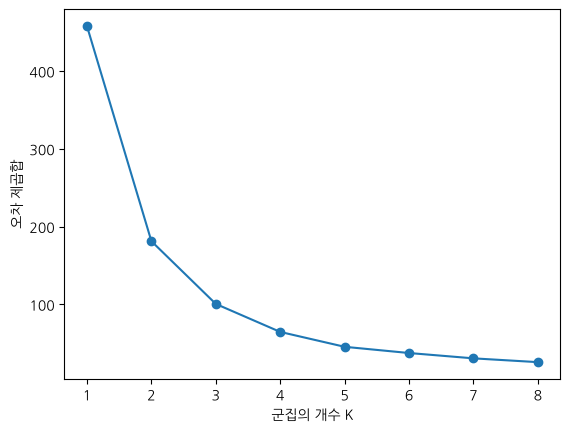

In [4]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import koreanize_matplotlib
X = df[['총인구', '고령인구비율']]
X_scaled = (X - X.mean()) / X.std(ddof=0)
# K를 1~8로 바꾸며 오차 제곱합 계산
sse = []
for k in range(1, 9):
    km = KMeans(n_clusters=k, n_init=10,
                random_state=42)
    km.fit(X_scaled)
    sse.append(km.inertia_)
print([round(v, 1) for v in sse])
plt.plot(range(1, 9), sse, marker='o')
plt.xlabel('군집의 개수 K')
plt.ylabel('오차 제곱합')
plt.show()

## 활동3. 전국 K-means 군집 분석 (K=3)

In [5]:
km = KMeans(n_clusters=3, n_init=10,
            random_state=42)
df['군집'] = km.fit_predict(X_scaled)
# 군집별 지역 수와 평균 특성
print(df['군집'].value_counts().sort_index())
cols = ['총인구', '고령인구비율', '소멸위험지수']
print(df.groupby('군집')[cols].mean().round(2))

군집
0    96
1    87
2    46
Name: count, dtype: int64
          총인구  고령인구비율  소멸위험지수
군집                           
0   209950.08   22.12    0.53
1    49600.43   37.74    0.17
2   580307.33   17.46    0.74


## 활동4. 실습 1: 시도별 군집 분포와 공간 불평등

군집        0   1   2
시도                 
강원특별자치도   7  11   0
경기도      13   3  15
경상남도      5  11   2
경상북도      5  15   2
광주광역시     3   0   2
대구광역시     5   1   3
대전광역시     3   0   2
부산광역시    12   4   0
서울특별시    15   0  10
세종특별자치시   0   0   1
울산광역시     5   0   0
인천광역시     3   2   5
전라남도      6  16   0
전북특별자치도   3  10   1
제주특별자치도   1   0   1
충청남도      5   9   1
충청북도      5   5   1


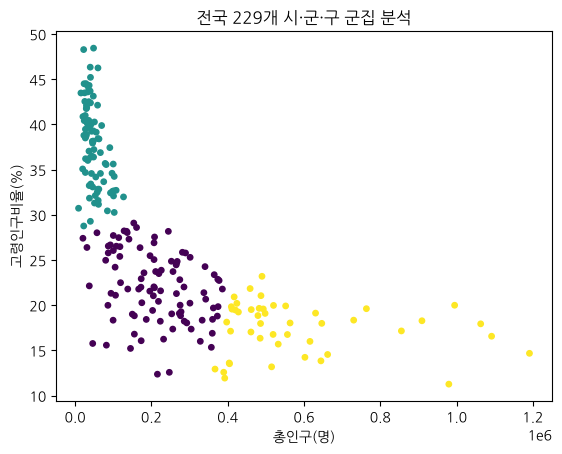

In [6]:
# 시도별로 각 군집에 속한 시·군·구 수
table = pd.crosstab(df['시도'], df['군집'])
print(table)
# 군집별 색으로 전국 산점도 그리기
x, y = df['총인구'], df['고령인구비율']
plt.scatter(x, y, c=df['군집'], s=15)
plt.xlabel('총인구(명)')
plt.ylabel('고령인구비율(%)')
plt.title('전국 229개 시·군·구 군집 분석')
plt.show()

## 활동5. 실습 2: 같은 유형의 지역 찾기

In [7]:
# 포항시와 같은 유형의 다른 지역 찾기
is_ph = (df['시도'] == '경상북도') & \
        (df['시군구'] == '포항시')
my_c = df[is_ph]['군집'].values[0]
same = df[df['군집'] == my_c]
print(f"포항시와 같은 유형: {len(same)}개 지역")
big = same.sort_values('총인구', ascending=False)
print(big[['시도', '시군구']].head(10))

포항시와 같은 유형: 46개 지역
       시도   시군구
75    경기도   수원시
93    경기도   용인시
84    경기도   고양시
216  경상남도   창원시
98    경기도   화성시
76    경기도   성남시
126  충청북도   청주시
79    경기도   부천시
87    경기도  남양주시
135  충청남도   천안시


## 모둠활동지 1 | 데이터 기반 인구 정책 제안서
아래 코드로 `우리 시도` 열을 채우고 유형별 정책을 제안해봅시다. (A~C는 평균 특성으로 군집 번호와 대응)

| 구분 | A 유형 | B 유형 | C 유형 | 우리 시도 | 전국 평균 |
|---|---|---|---|---|---|
| 지역 수(전국) | 46 | 96 | 87 | | 229 |
| 평균 총인구(명) | 580,307 | 209,950 | 49,600 | | 223,426 |
| 평균 고령인구비율(%) | 17.46 | 22.12 | 37.74 | | 27.12 |
| 평균 소멸위험지수 | 0.74 | 0.53 | 0.17 | | 0.43 |
| 정책 제안(핵심어) | | | | | - |

In [8]:
DATA_URL = BASE + 'korea_2025.csv'
import pandas as pd
from sklearn.cluster import KMeans
df = pd.read_csv(DATA_URL)
df['고령인구비율'] = df['고령인구'] / df['총인구'] * 100
df['소멸위험지수'] = df['청년여성인구'] / df['고령인구']
X = df[['총인구', '고령인구비율']]
X_scaled = (X - X.mean()) / X.std(ddof=0)
km = KMeans(n_clusters=3, n_init=10, random_state=42)
df['군집'] = km.fit_predict(X_scaled)
# 1. 모둠이 분석할 시도를 정해봅시다.
my_sido = '경상북도'
part = df[df['시도'] == my_sido]
# 2. 우리 시도의 유형별 지역 수와 평균(표의 '우리 시도' 열 채우기)
print(part['군집'].value_counts().sort_index())
cols = ['총인구', '고령인구비율', '소멸위험지수']
print(part[cols].mean().round(2))
# 3. 군집별 소속 지역 확인
for c in range(3):
    names = list(part[part['군집'] == c]['시군구'])
    print(f"군집 {c}: {names}")
# 4. 학생 코드 작성 부분(정책 제안의 근거 데이터를 추가로 분석해봅시다.)

군집
0     5
1    15
2     2
Name: count, dtype: int64
총인구       114521.55
고령인구비율        34.24
소멸위험지수         0.23
dtype: float64
군집 0: ['경주시', '김천시', '안동시', '경산시', '칠곡군']
군집 1: ['영주시', '영천시', '상주시', '문경시', '의성군', '청송군', '영양군', '영덕군', '청도군', '고령군', '성주군', '예천군', '봉화군', '울진군', '울릉군']
군집 2: ['포항시', '구미시']


## 모둠활동지 2 | 공간 불평등 해석과 상호 평가

**Q1.** 전국 군집 분석 결과에서 수도권과 비수도권의 군집 분포와 소멸위험지역 비율은 어떻게 다른가요? 이를 공간 불평등의 관점에서 설명해봅시다.

> **모범답안** 수도권(서울·경기·인천) 66개 시·군·구 중 소멸위험지역은 12개(18.2%)이지만, 비수도권은 163개 중 132개(81.0%)입니다. 서울은 25개 구 중 고령·소규모형이 한 곳도 없는 반면, 전남은 22곳 중 16곳, 경북은 22곳 중 15곳이 고령·소규모형에 속합니다. 일자리, 교육, 의료 등의 기회가 수도권과 대도시에 집중되면서 청년층이 이동하고, 그 결과 지역에 따라 인구 구조와 생활 여건의 격차가 커지는 공간 불평등이 나타난다고 해석할 수 있습니다.

**Q2.** 2차시(경북만 분석)와 3차시(전국 분석)에서 경북 시·군이 나뉜 결과를 비교하고, 결과가 달라진 이유를 표준화의 기준(평균, 표준편차)과 관련지어 설명해봅시다.

> **모범답안** 2차시에서는 경북의 평균(총인구 114,522명, 고령인구비율 34.24%)과 표준편차를 기준으로 표준화했고, 3차시에서는 전국의 평균(총인구 223,426명, 고령인구비율 27.12%)과 표준편차를 기준으로 표준화했습니다. 기준이 달라지면 같은 지역이라도 z 값이 달라집니다. 그 결과 2차시에서 포항·구미와 같은 군집이던 경산시는 전국 분석에서 경주·김천·안동·칠곡과 같은 중간 규모형으로, 경북에서는 중간 유형이던 영주·영천·상주·문경 등은 전국 평균보다 고령인구비율이 훨씬 높아 고령·소규모형으로 분류되었습니다.

**Q3.** 우리 모둠의 정책 제안이 어떤 데이터에 근거하는지 정리하고, 다른 모둠의 제안 중 가장 인상적인 것과 그 이유를 써봅시다.

> **모범답안** (예시: 경상북도) 경북 22개 시·군 중 15곳이 고령·소규모형이며, 경북 평균 고령인구비율 34.24%는 전국 평균 27.12%보다 높고 평균 소멸위험지수 0.23은 전국 평균 0.43보다 낮습니다. 따라서 고령·소규모형 지역에는 방문 의료·돌봄 서비스와 인근 시·군의 공공시설 공동 이용을, 포항·구미 같은 대도시형 지역에는 청년 일자리와 주거 지원을 통해 경북 내 인구 거점 역할을 강화하는 정책을 제안할 수 있습니다.(모둠별 자유 응답)